In [ ]:
!pip install --upgrade numpy scipy river -q

import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn, xgboost, river
from scipy.stats import ks_2samp
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from xgboost import XGBClassifier
from river import drift, forest
from tqdm.auto import tqdm
from google.colab import drive

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
ART = '/content/drive/MyDrive/nids_project/artifacts'

preprocess = joblib.load(f'{ART}/preprocess.joblib')
meta = json.load(open(f'{ART}/meta.json'))
train_df = pd.read_parquet(f'{ART}/train.parquet')
test_df = pd.read_parquet(f'{ART}/test.parquet')

pool = pd.concat([train_df, test_df], ignore_index=True).drop(columns=['id'], errors='ignore')
feature_cols = meta['raw_feature_order']
num_feature_names = meta['skewed_cols'] + meta['regular_cols']
print(pool.shape)
print(pool['attack_cat'].value_counts())

#experiment config
SEED = 42
WIN = 1000               # rows per window
N_WIN = 60               # windows in the stream
WARMUP_N = 30000         # rows for the initial model
ATTACK_RATIO = 0.40
DRIFT1_WIN = 20          # abrupt drift: new attack families appear
NEW_SHARE = 0.85         # share of attacks from new families after drift 1
DRIFT2_START, DRIFT2_END = 40, 50   # gradual drift: traffic volume grows
MAX_FACTOR = 5.0
OLD_FAMILIES = ['Generic', 'Exploits', 'Fuzzers', 'DoS']
VOLUME_COLS = [c for c in ['sbytes', 'dbytes', 'sload', 'dload', 'spkts', 'dpkts', 'rate']
               if c in pool.columns]
print('Volume columns that drift:', VOLUME_COLS)

(257673, 44)
attack_cat
Normal            93000
Generic           58871
Exploits          44525
Fuzzers           24246
DoS               16353
Reconnaissance    13987
Analysis           2677
Backdoor           2329
Shellcode          1511
Worms               174
Name: count, dtype: int64
Volume columns that drift: ['sbytes', 'dbytes', 'sload', 'dload', 'spkts', 'dpkts', 'rate']


In [ ]:
rng = np.random.default_rng(SEED)

is_normal = pool['attack_cat'].eq('Normal')
is_old = pool['attack_cat'].isin(OLD_FAMILIES)
is_new = ~is_normal & ~is_old

class RowPool:
    """Hands out row indices without repeats (reshuffles only if exhausted)."""
    def __init__(self, idx):
        self.idx, self.ptr, self.wraps = rng.permutation(idx), 0, 0
    def take(self, n):
        if n <= 0:
            return np.array([], dtype=int)
        out = []
        while n > 0:
            if self.ptr >= len(self.idx):
                self.idx, self.ptr, self.wraps = rng.permutation(self.idx), 0, self.wraps + 1
            k = min(n, len(self.idx) - self.ptr)
            out.append(self.idx[self.ptr:self.ptr + k]); self.ptr += k; n -= k
        return np.concatenate(out)

P_norm = RowPool(np.where(is_normal)[0])
P_old = RowPool(np.where(is_old)[0])
P_new = RowPool(np.where(is_new)[0])

def make_batch(n, new_share):
    n_att = int(round(n * ATTACK_RATIO))
    n_new = int(round(n_att * new_share))
    idx = np.concatenate([P_norm.take(n - n_att), P_old.take(n_att - n_new), P_new.take(n_new)])
    return rng.permutation(idx)

def vol_factor(w):
    if w < DRIFT2_START: return 1.0
    if w >= DRIFT2_END: return MAX_FACTOR
    return 1.0 + (MAX_FACTOR - 1.0) * (w - DRIFT2_START + 1) / (DRIFT2_END - DRIFT2_START)

# warm-up: old regime only
warm = pool.iloc[make_batch(WARMUP_N, 0.0)].reset_index(drop=True)

# stream
all_idx = np.concatenate([make_batch(WIN, NEW_SHARE if w >= DRIFT1_WIN else 0.0) for w in range(N_WIN)])
stream = pool.iloc[all_idx].reset_index(drop=True)
stream['window'] = np.repeat(np.arange(N_WIN), WIN)
stream['factor'] = stream['window'].map(vol_factor)
stream[VOLUME_COLS] = stream[VOLUME_COLS].astype(float).mul(stream['factor'], axis=0)
stream['group'] = np.where(stream['attack_cat'].eq('Normal'), 'Normal',
                  np.where(stream['attack_cat'].isin(OLD_FAMILIES), 'Old attacks', 'New attacks'))

# model-ready arrays
X_warm = preprocess.transform(warm[feature_cols]); y_warm = warm['label'].values.astype(int)
X_stream = preprocess.transform(stream[feature_cols]); y_stream = stream['label'].values.astype(int)
feature_names = preprocess.get_feature_names_out()
n_num = len(num_feature_names)          # numeric columns come first in the transformed matrix
win_idx = [np.where(stream['window'].values == w)[0] for w in range(N_WIN)]

print('warm-up:', X_warm.shape, ' stream:', X_stream.shape)
print('pool wrap-arounds (should be 0):', P_norm.wraps, P_old.wraps, P_new.wraps)

warm-up: (30000, 69)  stream: (60000, 69)
pool wrap-arounds (should be 0): 0 0 0


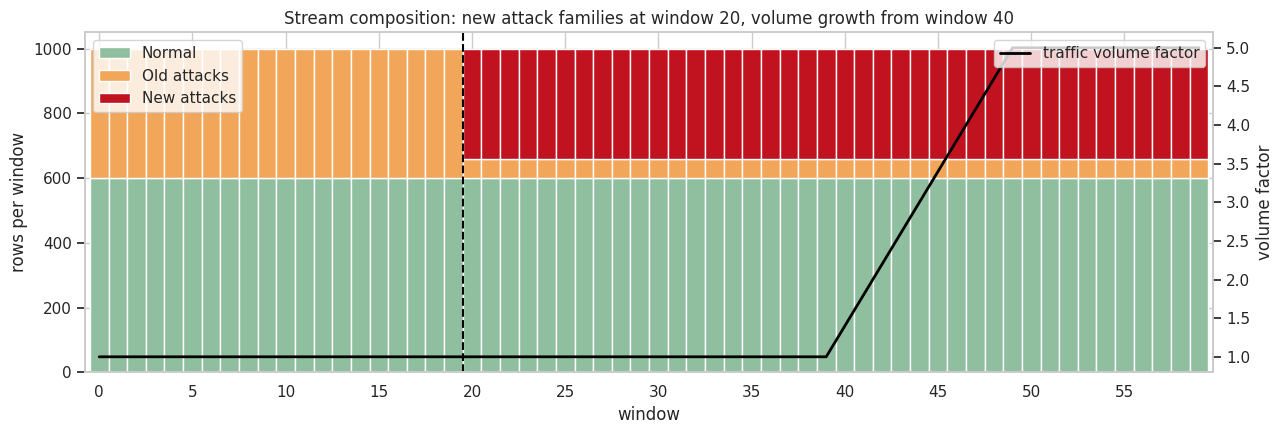

In [ ]:
comp = (stream.groupby(['window', 'group']).size().unstack(fill_value=0)
        [['Normal', 'Old attacks', 'New attacks']])

fig, ax = plt.subplots(figsize=(13, 4.5))
comp.plot.bar(stacked=True, ax=ax, width=1.0, color=['#8fbf9f', '#f2a65a', '#c1121f'])
ax.set_xticks(range(0, N_WIN, 5)); ax.set_xticklabels(range(0, N_WIN, 5), rotation=0)
ax.set_ylabel('rows per window'); ax.set_xlabel('window')

ax2 = ax.twinx()
ax2.plot(range(N_WIN), stream.groupby('window')['factor'].first().values,
         color='black', lw=2, label='traffic volume factor')
ax2.set_ylabel('volume factor'); ax2.grid(False)
ax.axvline(DRIFT1_WIN - 0.5, color='black', ls='--')
ax.set_title('Stream composition: new attack families at window 20, volume growth from window 40')
ax.legend(loc='upper left'); ax2.legend(loc='upper right')
plt.tight_layout(); plt.show()

Mean F1 pre-drift (0-19):    0.9314
Mean F1 after drift 1 (20-39): 0.8049
Mean F1 after drift 2 (50-59): 0.8755


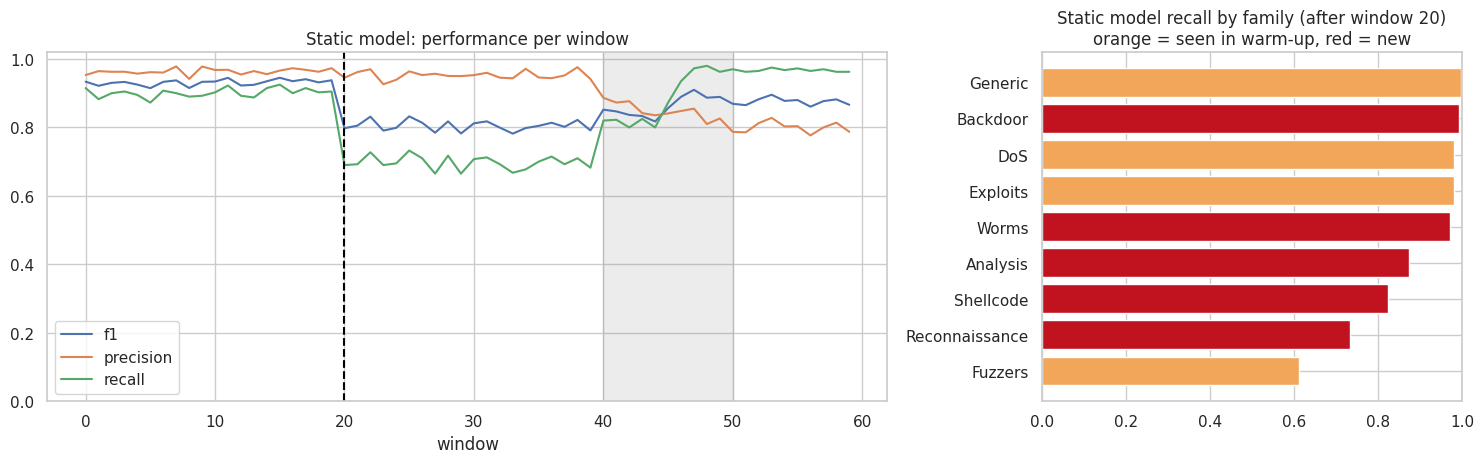

,mean,size
attack_cat,,
Fuzzers,0.612821,390
Reconnaissance,0.732521,9197
Shellcode,0.825052,966
Analysis,0.874930,1791
Worms,0.972222,108
Exploits,0.980132,755
DoS,0.980843,261
Backdoor,0.994148,1538
Generic,0.997988,994


In [ ]:
xgb_params = dict(n_estimators=200, max_depth=6, learning_rate=0.1, subsample=0.8,
                  colsample_bytree=0.8, tree_method='hist', n_jobs=-1,
                  random_state=SEED, eval_metric='logloss')

def per_window_metrics(y_true, y_pred, windows):
    rows = []
    for w in np.unique(windows):
        m = windows == w
        rows.append(dict(window=w,
                         accuracy=accuracy_score(y_true[m], y_pred[m]),
                         precision=precision_score(y_true[m], y_pred[m], zero_division=0),
                         recall=recall_score(y_true[m], y_pred[m], zero_division=0),
                         f1=f1_score(y_true[m], y_pred[m], zero_division=0)))
    return pd.DataFrame(rows).set_index('window')

init_model = XGBClassifier(**xgb_params).fit(X_warm, y_warm)
static_pred = init_model.predict(X_stream)
static_metrics = per_window_metrics(y_stream, static_pred, stream['window'].values)

print('Mean F1 pre-drift (0-19):   ', round(static_metrics.loc[:19, 'f1'].mean(), 4))
print('Mean F1 after drift 1 (20-39):', round(static_metrics.loc[20:39, 'f1'].mean(), 4))
print('Mean F1 after drift 2 (50-59):', round(static_metrics.loc[50:, 'f1'].mean(), 4))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={'width_ratios': [2, 1]})
for m in ['f1', 'precision', 'recall']:
    axes[0].plot(static_metrics.index, static_metrics[m], label=m)
axes[0].axvline(DRIFT1_WIN, color='black', ls='--')
axes[0].axvspan(DRIFT2_START, DRIFT2_END, color='grey', alpha=0.15)
axes[0].set_title('Static model: performance per window'); axes[0].set_xlabel('window')
axes[0].set_ylim(0, 1.02); axes[0].legend()

post = stream['window'] >= DRIFT1_WIN
att = stream[(stream['label'] == 1) & post].copy()
att['hit'] = static_pred[att.index.values] == 1
fam = att.groupby('attack_cat')['hit'].agg(['mean', 'size']).sort_values('mean')
cols = ['#f2a65a' if c in OLD_FAMILIES else '#c1121f' for c in fam.index]
axes[1].barh(fam.index, fam['mean'], color=cols)
axes[1].set_title('Static model recall by family (after window 20)\norange = seen in warm-up, red = new')
axes[1].set_xlim(0, 1)
plt.tight_layout(); plt.show()
display(fam)

In [ ]:
errors = (static_pred != y_stream).astype(int)

adwin = drift.ADWIN(delta=0.002)
adwin_alarms = []    # row index of each alarm
for i, e in enumerate(errors):
    adwin.update(int(e))
    if adwin.drift_detected:
        adwin_alarms.append(i)

print('ADWIN alarm rows:', adwin_alarms)
print('ADWIN alarm windows:', sorted({a // WIN for a in adwin_alarms}))

ADWIN alarm rows: [20287, 47327]
ADWIN alarm windows: [20, 47]


In [ ]:
ref_idx = np.random.default_rng(SEED).choice(len(X_warm), 5000, replace=False)
X_ref = X_warm[ref_idx][:, :n_num]

KS_ALPHA = 0.001     # family-wise, Bonferroni-corrected across features
KS_FRAC = 0.10       # drift if at least 10% of numeric features reject

def ks_check(ref, cur):
    pvals = np.array([ks_2samp(ref[:, j], cur[:, j]).pvalue for j in range(ref.shape[1])])
    return float((pvals < KS_ALPHA / ref.shape[1]).mean())

ks_df = pd.DataFrame({'window': range(N_WIN),
                      'frac_rejected': [ks_check(X_ref, X_stream[idx][:, :n_num]) for idx in win_idx]}
                     ).set_index('window')
ks_df['drift'] = ks_df['frac_rejected'] >= KS_FRAC
print('KS alarm windows:', ks_df.index[ks_df['drift']].tolist())

KS alarm windows: [20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59]


ADWIN  false alarms before drift 1: []
ADWIN  detection delay for drift 1 (rows): 287
ADWIN  alarms during/after drift 2 (windows): [47]
KS     false alarms before drift 1 (windows): []
KS     detection delay for drift 1 (windows): 0
KS     mean fraction of features rejected  pre / mid / late: 0.0 0.242 0.387


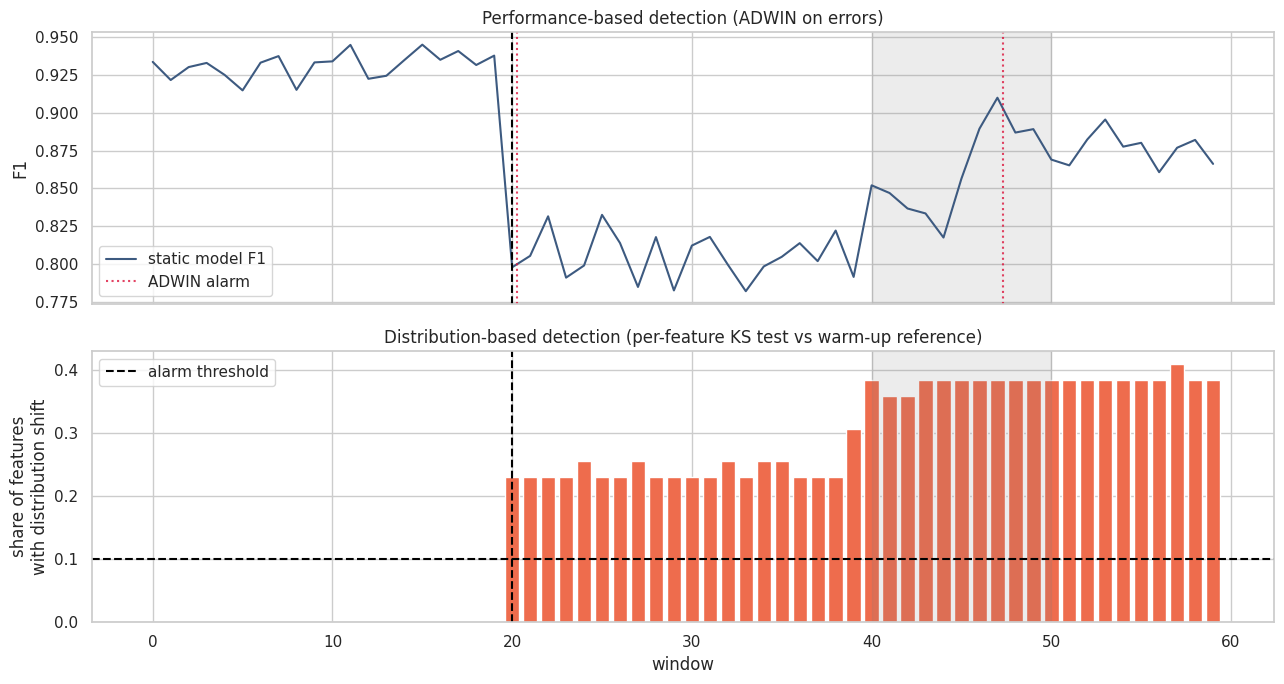

In [ ]:
adwin_win = sorted({a // WIN for a in adwin_alarms})
ks_win = ks_df.index[ks_df['drift']].tolist()

first_adwin = next((a for a in adwin_alarms if a >= DRIFT1_WIN * WIN), None)
first_ks = next((w for w in ks_win if w >= DRIFT1_WIN), None)

print('ADWIN  false alarms before drift 1:', [a for a in adwin_alarms if a < DRIFT1_WIN * WIN])
print('ADWIN  detection delay for drift 1 (rows):',
      None if first_adwin is None else first_adwin - DRIFT1_WIN * WIN)
print('ADWIN  alarms during/after drift 2 (windows):', [w for w in adwin_win if w >= DRIFT2_START])
print('KS     false alarms before drift 1 (windows):', [w for w in ks_win if w < DRIFT1_WIN])
print('KS     detection delay for drift 1 (windows):',
      None if first_ks is None else first_ks - DRIFT1_WIN)
print('KS     mean fraction of features rejected  pre / mid / late:',
      ks_df.loc[:19, 'frac_rejected'].mean().round(3),
      ks_df.loc[22:39, 'frac_rejected'].mean().round(3),
      ks_df.loc[50:, 'frac_rejected'].mean().round(3))

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(static_metrics.index, static_metrics['f1'], color='#3D5A80', label='static model F1')
for k, a in enumerate(adwin_alarms):
    axes[0].axvline(a / WIN, color='crimson', ls=':', alpha=0.8, label='ADWIN alarm' if k == 0 else None)
axes[0].set_ylabel('F1'); axes[0].set_title('Performance-based detection (ADWIN on errors)')
axes[0].legend(loc='lower left')

axes[1].bar(ks_df.index, ks_df['frac_rejected'], color='#EE6C4D')
axes[1].axhline(KS_FRAC, color='black', ls='--', label='alarm threshold')
axes[1].set_ylabel('share of features\nwith distribution shift'); axes[1].set_xlabel('window')
axes[1].set_title('Distribution-based detection (per-feature KS test vs warm-up reference)')
axes[1].legend()

for ax in axes:
    ax.axvline(DRIFT1_WIN, color='black', ls='--')
    ax.axvspan(DRIFT2_START, DRIFT2_END, color='grey', alpha=0.15)
plt.tight_layout(); plt.show()

In [ ]:
RETRAIN_BUFFER = 6      # windows of labelled data used for retraining
COOLDOWN = 2            # windows to wait after a retrain before another trigger
CONSOLIDATE_AFTER = 3   # extra retrain this many windows after a trigger, once more post-drift data exists

model = init_model
det = drift.ADWIN(delta=0.002)
ref = X_ref
trig_pred = np.zeros(len(stream), dtype=int)
retrain_log, last_retrain, pending = [], -99, None

for w in range(N_WIN):
    idx = win_idx[w]
    pred = model.predict(X_stream[idx])
    trig_pred[idx] = pred                      # predict first, labels arrive afterwards

    adwin_fired = False
    for e in (pred != y_stream[idx]).astype(int):
        det.update(int(e))
        adwin_fired = adwin_fired or det.drift_detected
    frac = ks_check(ref, X_stream[idx][:, :n_num])
    ks_fired = frac >= KS_FRAC

    trigger = (adwin_fired or ks_fired) and (w - last_retrain > COOLDOWN)
    consolidate = pending is not None and w == pending
    if trigger or consolidate:
        buf = np.concatenate(win_idx[max(0, w - RETRAIN_BUFFER + 1): w + 1])
        model = XGBClassifier(**xgb_params).fit(X_stream[buf], y_stream[buf])
        ref = X_stream[idx][:, :n_num]
        det = drift.ADWIN(delta=0.002)
        last_retrain = w
        pending = w + CONSOLIDATE_AFTER if trigger else None
        retrain_log.append(dict(window=w, reason='drift' if trigger else 'consolidate',
                                adwin=bool(adwin_fired), ks=bool(ks_fired),
                                ks_frac=round(frac, 3), train_rows=len(buf)))

trig_metrics = per_window_metrics(y_stream, trig_pred, stream['window'].values)
display(pd.DataFrame(retrain_log))
print('Total retrains:', len(retrain_log))

,window,reason,adwin,ks,ks_frac,train_rows
0,20,drift,True,True,0.231,6000
1,23,consolidate,False,False,0.000,6000
2,40,drift,False,True,0.154,6000
3,43,drift,False,True,0.179,6000
4,46,drift,False,True,0.154,6000
5,49,drift,False,True,0.154,6000
6,52,consolidate,False,False,0.000,6000


Total retrains: 7


In [ ]:
ARF_WARMUP_ROWS = 15000
N_TREES = 10
cols = list(feature_names)

def to_dict(row):
    return dict(zip(cols, row.tolist()))

arf = forest.ARFClassifier(n_models=N_TREES, seed=SEED)
t0 = time.time()
for i in tqdm(range(ARF_WARMUP_ROWS), desc='ARF warm-up'):
    arf.learn_one(to_dict(X_warm[i]), int(y_warm[i]))

arf_pred = np.zeros(len(stream), dtype=int)
for i in tqdm(range(len(stream)), desc='ARF prequential'):
    x = to_dict(X_stream[i])
    p = arf.predict_one(x)
    arf_pred[i] = int(p) if p is not None else 0
    arf.learn_one(x, int(y_stream[i]))
print(f'ARF done in {(time.time() - t0) / 60:.1f} min')

arf_metrics = per_window_metrics(y_stream, arf_pred, stream['window'].values)

ARF warm-up:   0%|          | 0/15000 [00:00<?, ?it/s]

ARF prequential:   0%|          | 0/60000 [00:00<?, ?it/s]

ARF done in 3.1 min


,pre-drift (0-19),new attacks (20-39),gradual drift (40-49),after (50-59),F1 on all post-drift rows,recall on all post-drift rows
Static (no adaptation),0.9314,0.8049,0.8618,0.8755,0.8405,0.8101
Drift-triggered retrain,0.9314,0.9460,0.9481,0.9591,0.9503,0.9438
Online ARF,0.9107,0.9411,0.9385,0.9467,0.9419,0.9345


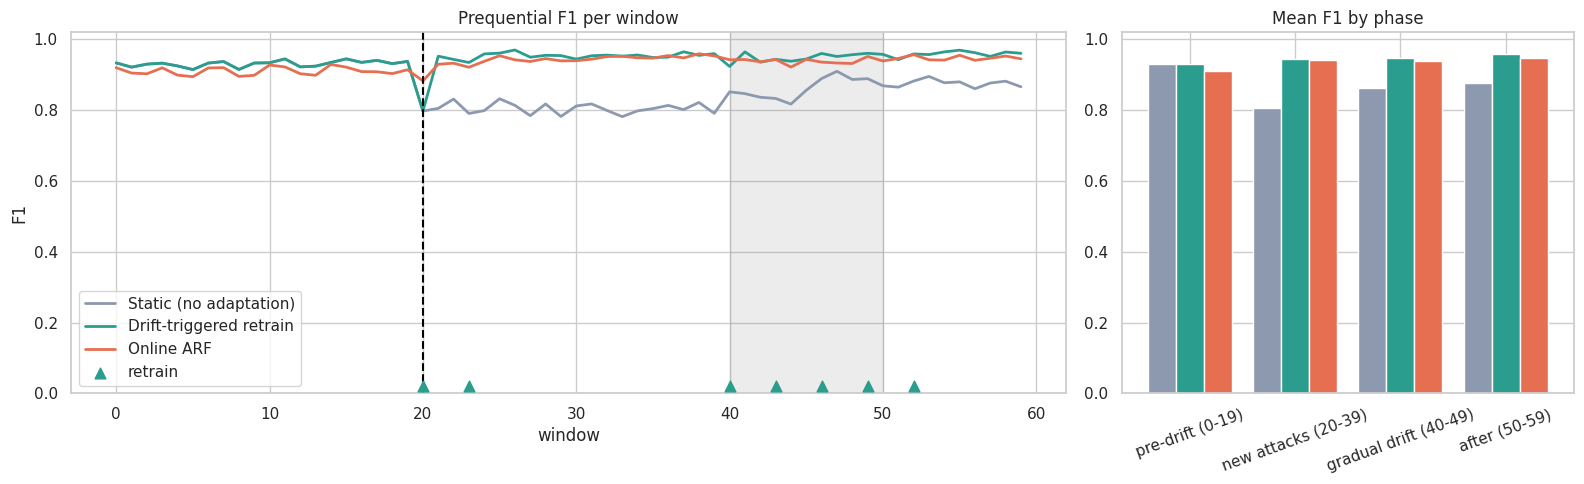

In [ ]:
strategies = {'Static (no adaptation)': (static_metrics, static_pred),
              'Drift-triggered retrain': (trig_metrics, trig_pred),
              'Online ARF': (arf_metrics, arf_pred)}
phases = {'pre-drift (0-19)': range(0, 20), 'new attacks (20-39)': range(20, 40),
          'gradual drift (40-49)': range(40, 50), 'after (50-59)': range(50, 60)}
post_rows = (stream['window'] >= DRIFT1_WIN).values

summary = pd.DataFrame({
    name: {**{ph: m.loc[list(r), 'f1'].mean() for ph, r in phases.items()},
           'F1 on all post-drift rows': f1_score(y_stream[post_rows], p[post_rows]),
           'recall on all post-drift rows': recall_score(y_stream[post_rows], p[post_rows])}
    for name, (m, p) in strategies.items()}).T.round(4)
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={'width_ratios': [2.2, 1]})
colors = ['#8d99ae', '#2a9d8f', '#e76f51']
for (name, (m, _)), c in zip(strategies.items(), colors):
    axes[0].plot(m.index, m['f1'], label=name, color=c, lw=2)
for k, r in enumerate(retrain_log):
    axes[0].scatter(r['window'], 0.02, marker='^', color='#2a9d8f', s=60,
                    label='retrain' if k == 0 else None, zorder=5)
axes[0].axvline(DRIFT1_WIN, color='black', ls='--')
axes[0].axvspan(DRIFT2_START, DRIFT2_END, color='grey', alpha=0.15)
axes[0].set_ylim(0, 1.02); axes[0].set_xlabel('window'); axes[0].set_ylabel('F1')
axes[0].set_title('Prequential F1 per window'); axes[0].legend(loc='lower left')

summary[list(phases)].T.plot.bar(ax=axes[1], color=colors, width=0.8, legend=False)
axes[1].set_title('Mean F1 by phase'); axes[1].set_ylim(0, 1.02)
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

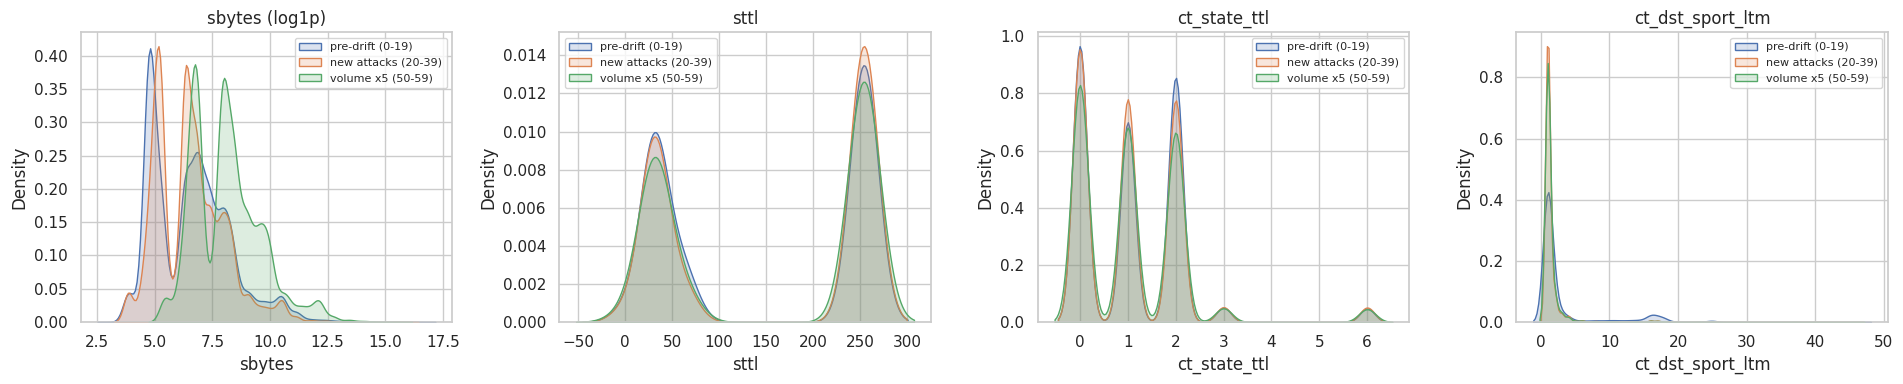

In [ ]:
numeric_top = [c for c in meta['top_raw_features'] if c in num_feature_names]
show = list(dict.fromkeys(['sbytes'] + numeric_top))[:4]
regimes = {'pre-drift (0-19)': range(0, 20), 'new attacks (20-39)': range(20, 40),
           'volume x5 (50-59)': range(50, 60)}

fig, axes = plt.subplots(1, len(show), figsize=(4.8 * len(show), 4))
for ax, c in zip(np.atleast_1d(axes), show):
    for name, r in regimes.items():
        s = stream.loc[stream['window'].isin(list(r)), c].astype(float)
        vals = np.log1p(s.clip(lower=0)) if c in meta['skewed_cols'] else s
        sns.kdeplot(vals, ax=ax, label=name, fill=True, alpha=0.2, common_norm=False)
    ax.set_title(c + (' (log1p)' if c in meta['skewed_cols'] else ''))
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
OUT = f'{ART}/day2'
os.makedirs(OUT, exist_ok=True)

stream_out = stream.copy()
stream_out['pred_static'] = static_pred
stream_out['pred_triggered'] = trig_pred
stream_out['pred_arf'] = arf_pred
stream_out.to_parquet(f'{OUT}/stream.parquet')
warm.sample(5000, random_state=SEED).to_parquet(f'{OUT}/warmup_reference.parquet')

all_metrics = pd.concat({n: m for n, (m, _) in strategies.items()}, names=['strategy']).reset_index()
all_metrics.to_csv(f'{OUT}/window_metrics.csv', index=False)
summary.to_csv(f'{OUT}/strategy_summary.csv')

events = dict(
    config=dict(WIN=WIN, N_WIN=N_WIN, WARMUP_N=WARMUP_N, ATTACK_RATIO=ATTACK_RATIO,
                DRIFT1_WIN=DRIFT1_WIN, NEW_SHARE=NEW_SHARE, DRIFT2_START=DRIFT2_START,
                DRIFT2_END=DRIFT2_END, MAX_FACTOR=MAX_FACTOR, OLD_FAMILIES=OLD_FAMILIES,
                VOLUME_COLS=VOLUME_COLS, KS_ALPHA=KS_ALPHA, KS_FRAC=KS_FRAC),
    true_drifts=[dict(type='abrupt', window=DRIFT1_WIN),
                 dict(type='gradual', start=DRIFT2_START, end=DRIFT2_END)],
    adwin_alarm_rows=adwin_alarms,
    ks_frac_by_window=ks_df['frac_rejected'].round(4).tolist(),
    retrains=retrain_log,
    versions=dict(sklearn=sklearn.__version__, xgboost=xgboost.__version__,
                  river=river.__version__, pandas=pd.__version__, numpy=np.__version__))
json.dump(events, open(f'{OUT}/drift_events.json', 'w'), indent=2,
          default=lambda o: o.item() if hasattr(o, 'item') else str(o))

joblib.dump(init_model, f'{OUT}/model_initial.joblib')
joblib.dump(model, f'{OUT}/model_adapted.joblib')       # last model produced by drift-triggered retraining
joblib.dump(arf, f'{OUT}/model_arf.joblib')

for f in sorted(os.listdir(OUT)):
    print(f'{os.path.getsize(f"{OUT}/{f}") / 1e6:8.1f} MB  {f}')

     0.0 MB  drift_events.json
     0.5 MB  model_adapted.joblib
    74.7 MB  model_arf.joblib
     0.6 MB  model_initial.joblib
     0.0 MB  strategy_summary.csv
     5.6 MB  stream.parquet
     0.5 MB  warmup_reference.parquet
     0.0 MB  window_metrics.csv


In [ ]:
init_model.save_model(f'{OUT}/model_initial.json')
model.save_model(f'{OUT}/model_adapted.json')